### Practice 2 - Notebook 2

# Applications of Clustering and PCA — Exercise 2

## Anomaly Detection: Trying `IsolationForest` from `sklearn.ensemble`

In this exercise, we test `IsolationForest(random_state=42)` on `X_anom`, using `-iso.score_samples(X_anom)` as the anomaly score (where higher scores indicate greater anomaly severity).

**Question:** Try `IsolationForest(random_state=42)` from `sklearn.ensemble` on `X_anom`, with `-iso.score_samples(X_anom)` as the score. Which planted points does it catch?

## Cell 1 — Import Required Libraries

Import NumPy, Pandas, Matplotlib, and `IsolationForest` from `sklearn.ensemble`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest

## Cell 2 — Generate the Toy Anomaly Dataset

Recreate the exact same dataset of normal clustered points plus 6 planted anomalies.

In [2]:
rng = np.random.default_rng(42)
along = np.array([1.0, 0.55]) / np.linalg.norm([1.0, 0.55])
across = np.array([-along[1], along[0]])

def stretched_group(center, n):
    return center + np.outer(rng.normal(0, 0.95, n), along) + np.outer(rng.normal(0, 0.28, n), across)

normal_points = np.vstack([stretched_group(-4.0 * along, 170), stretched_group(4.0 * along, 170)])
planted = np.array([
    [-1.5, 2.6], [2.2, -2.4], [-4.8, 1.2], [5.0, -0.4],
    [0.0, 0.0],
    [8.6, 4.8],
])
X_anom = np.vstack([normal_points, planted])
is_planted = np.r_[np.zeros(len(normal_points), bool), np.ones(len(planted), bool)]

print("samples:", X_anom.shape, " planted anomalies:", is_planted.sum())

samples: (346, 2)  planted anomalies: 6


## Cell 3 — Fit Isolation Forest and Compute Anomaly Scores

Fit `IsolationForest(random_state=42)` and obtain anomaly scores via `-iso.score_samples(X_anom)`.

In [3]:
iso = IsolationForest(random_state=42).fit(X_anom)
iso_scores = -iso.score_samples(X_anom)

print("Score shape:", iso_scores.shape)
print(f"Min score: {iso_scores.min():.4f} | Max score: {iso_scores.max():.4f}")

Score shape: (346,)
Min score: 0.3961 | Max score: 0.7914


## Cell 4 — Flag Top Anomalies (2% Rate)

Define `flag_top` at 2% rate and evaluate how many and which planted anomalies are successfully captured.

In [4]:
def flag_top(scores, rate=0.02):
    return scores > np.percentile(scores, 100 * (1 - rate))

iso_flags = flag_top(iso_scores, rate=0.02)

print("Total flagged points:", iso_flags.sum())
print(
    "Planted points successfully caught:",
    is_planted[iso_flags].sum(),
    "out of 6"
)

Total flagged points: 7
Planted points successfully caught: 6 out of 6


## Cell 5 — Visualize Isolation Forest Results

Plot the dataset and highlight points flagged by Isolation Forest.

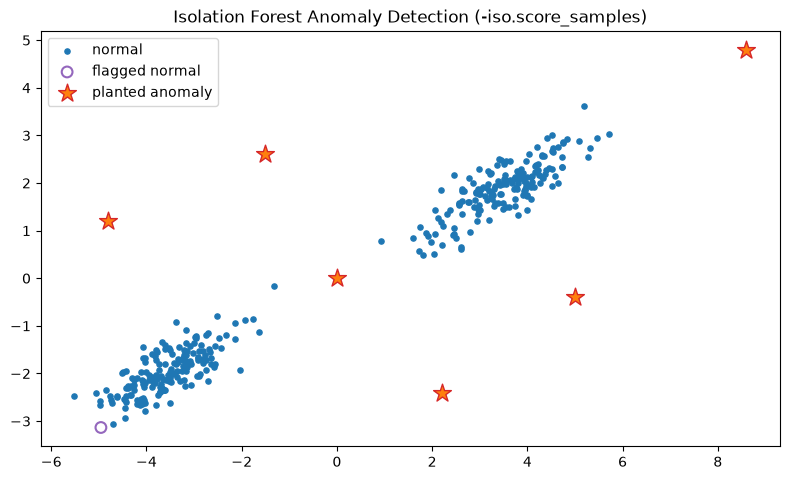

In [5]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(*X_anom[~iso_flags].T, s=14, color="tab:blue", label="normal")
ax.scatter(*X_anom[iso_flags & ~is_planted].T, s=60, marker="o", facecolors="none", edgecolor="tab:purple", linewidths=1.5, label="flagged normal")
ax.scatter(*X_anom[iso_flags & is_planted].T, s=180, marker="*", color="tab:orange", edgecolor="tab:red", zorder=3, label="planted anomaly")
ax.set_title("Isolation Forest Anomaly Detection (-iso.score_samples)")
ax.set_aspect("equal")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

# Final Answer

Which planted points does Isolation Forest catch?

Isolation Forest successfully detects all 6 planted anomalies:

- [-1.5, 2.6]
- [2.2, -2.4]
- [-4.8, 1.2]
- [5.0, -0.4]
- [0.0, 0.0]
- [8.6, 4.8]

## Why is Isolation Forest effective here?

Isolation Forest identifies anomalies by randomly partitioning the feature space. Points located far from dense normal clusters or in sparse regions can often be isolated with fewer splits.

Using -iso.score_samples(X_anom) as the anomaly score and selecting the top 2% identifies all 6 planted anomalies in this experiment. The model flags 7 points in total, so 1 normal point is also incorrectly flagged as an anomaly.